# 13. Fit parameters and their covariance

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 11 and 12

**Reading:** Bevington & Robinson, ch. 6–7 · Fornasini, ch. 10.4 · Rouaud,
ch. II.C–D · Deming, *Statistical Adjustment of Data* · York et al. (2004)

A fit is rarely the end of an analysis. The fitted parameters are fed into
further formulas: a predicted value at some new $x$, an intercept with an
axis, an activation energy, a half-life. Parameters obtained from the same
data are correlated, and by Section 12.2 any quantity computed from more
than one of them needs their covariance matrix. Quoting "$a \pm u_a$,
$b \pm u_b$" and nothing else discards information that the reader cannot
reconstruct.

This notebook

1. derives the parameter covariance matrix of linear least squares;
2. shows its consequences on a classic extrapolation, the gas-thermometer
   estimate of absolute zero;
3. shows how centring the data removes the correlation;
4. examines what happens to the weights when data are transformed to make
   a model linear;
5. discusses unknown error bars, and errors in both variables.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.optimize import curve_fit

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(16)

## 13.1 Linear least squares in matrix form

A model is *linear in its parameters* if it can be written as

$$ y_i = \sum_{j=1}^{p} A_{ij}\,\beta_j , \qquad\text{or}\qquad \boldsymbol y = \mathsf A\boldsymbol\beta , $$

where the **design matrix** $\mathsf A$ contains known functions of $x$.
For a straight line the columns of $\mathsf A$ are $1$ and $x_i$; for a
polynomial they are $1, x_i, x_i^2, \dots$ The model need not be linear in
$x$.

With independent data of standard uncertainties $\sigma_i$, collect the
weights in $\mathsf W = \operatorname{diag}(1/\sigma_i^2)$, which is the
inverse of the data covariance matrix $\mathsf C_y$. Then

$$ \chi^2(\boldsymbol\beta) = (\boldsymbol y - \mathsf A\boldsymbol\beta)^{\mathsf T}\,\mathsf W\,(\boldsymbol y - \mathsf A\boldsymbol\beta) . $$

Setting the gradient with respect to $\boldsymbol\beta$ to zero gives the
**normal equations**
$\mathsf A^{\mathsf T}\mathsf W\mathsf A\,\boldsymbol\beta = \mathsf A^{\mathsf T}\mathsf W\boldsymbol y$,
with solution

$$ \hat{\boldsymbol\beta} = \mathsf K\,\boldsymbol y , \qquad
   \mathsf K = (\mathsf A^{\mathsf T}\mathsf W\mathsf A)^{-1}\mathsf A^{\mathsf T}\mathsf W . $$

The estimate is a linear function of the data, so the general propagation
law $\mathsf C_\beta = \mathsf K\,\mathsf C_y\,\mathsf K^{\mathsf T}$ of
Section 12.1 applies exactly. With $\mathsf C_y = \mathsf W^{-1}$,

$$ \mathsf C_\beta = (\mathsf A^{\mathsf T}\mathsf W\mathsf A)^{-1}\mathsf A^{\mathsf T}\mathsf W\,\mathsf W^{-1}\,\mathsf W\mathsf A\,(\mathsf A^{\mathsf T}\mathsf W\mathsf A)^{-1} , $$

which collapses to

> $$ \mathsf C_\beta = (\mathsf A^{\mathsf T}\mathsf W\mathsf A)^{-1} . $$

The diagonal elements are the squared parameter uncertainties; the
off-diagonal elements are their covariances.

### The straight line

For $y = a + bx$ with equal uncertainties $\sigma$,

$$ \mathsf A^{\mathsf T}\mathsf W\mathsf A = \frac{1}{\sigma^2}\begin{pmatrix} N & \sum x_i \\ \sum x_i & \sum x_i^2 \end{pmatrix},
 \qquad
 \mathsf C_\beta = \frac{\sigma^2}{S_{xx}}\begin{pmatrix} \tfrac1N\sum x_i^2 & -\bar x \\ -\bar x & 1 \end{pmatrix} , $$

using $N\sum x_i^2 - (\sum x_i)^2 = N S_{xx}$. The diagonal reproduces
$u_a^2$ and $u_b^2$ of Chapter 11. The new element is

$$ u_{ab} = -\frac{\bar x\,\sigma^2}{S_{xx}} , \qquad
   \rho_{ab} = -\frac{\bar x}{\sqrt{S_{xx}/N + \bar x^2}} . $$

If the data lie at positive $x$, slope and intercept are negatively
correlated. The reason is geometric: the line is pinned near the centroid
$(\bar x, \bar y)$ of the data, and a line that pivots there to a steeper
slope must cut the $y$-axis lower. The further the data are from $x = 0$
compared with their spread, the closer $\rho_{ab}$ is to $-1$.

## 13.2 Example: absolute zero from a gas thermometer

The pressure of a fixed amount of gas at constant volume is measured at
temperatures between 0 and 100 °C. For an ideal gas the pressure is linear
in the Celsius temperature $\theta$,

$$ P = a + b\,\theta , $$

and extrapolates to zero at $\theta_0 = -a/b$, the absolute zero. Two
derived quantities will be considered: the pressure predicted at 50 °C
(an interpolation) and $\theta_0$ (a long extrapolation, and a ratio of
the two correlated parameters). The data are simulated from an ideal gas
with $\theta_0 = -273.15$ °C and a pressure noise of 0.25 kPa.

In [2]:
theta0_true, P0_true, sigma_P = -273.15, 101.3, 0.25      # deg C, kPa, kPa
theta = np.arange(0.0, 101.0, 10.0)

def experiment():
    return P0_true * (1 - theta / theta0_true) + rng.normal(0, sigma_P, theta.size)

P = experiment()
fit = ep.linear_fit(theta, P, sigma=sigma_P)
print(fit)
print("\ncovariance matrix [intercept, slope]:\n", fit.cov)

intercept = 101.489 +/- 0.14
slope     = 0.367871 +/- 0.0024
correlation(intercept, slope) = -0.845
chi2 / dof = 7.48 / 9 = 0.83

covariance matrix [intercept, slope]:
 [[ 1.98863636e-02 -2.84090909e-04]
 [-2.84090909e-04  5.68181818e-06]]


### The two derived quantities

**Predicted pressure at $\theta^\ast$.** With $P^\ast = a + b\,\theta^\ast$
the sensitivity coefficients are $1$ and $\theta^\ast$, so

$$ u_{P^\ast}^2 = u_a^2 + \theta^{\ast 2}u_b^2 + 2\,\theta^\ast u_{ab} . $$

**Absolute zero.** With $\theta_0 = -a/b$ the coefficients are
$\partial\theta_0/\partial a = -1/b$ and
$\partial\theta_0/\partial b = a/b^2$, so

$$ u_{\theta_0}^2 = \frac{u_a^2}{b^2} + \frac{a^2u_b^2}{b^4} - \frac{2a}{b^3}\,u_{ab} . $$

Since $u_{ab} < 0$, the covariance term *reduces* the uncertainty of the
interpolated pressure and *increases* that of the extrapolated zero.

In [3]:
a, b, C = fit.intercept, fit.slope, fit.cov

P50, u_P50 = ep.propagate(lambda a, b: a + 50 * b, [a, b], cov=C)
_, u_P50_nocov = ep.propagate(lambda a, b: a + 50 * b, [a, b], u=np.sqrt(np.diag(C)))

zero = lambda a, b: -a / b
th0, u_th0 = ep.propagate(zero, [a, b], cov=C)
_, u_th0_nocov = ep.propagate(zero, [a, b], u=np.sqrt(np.diag(C)))

print(f"P(50 C)    = {P50:.3f} kPa")
print(f"   u with covariance    : {u_P50:.3f} kPa")
print(f"   u ignoring covariance: {u_P50_nocov:.3f} kPa")
print(f"absolute zero = {th0:.2f} C   (true value {theta0_true})")
print(f"   u with covariance    : {u_th0:.2f} K")
print(f"   u ignoring covariance: {u_th0_nocov:.2f} K")

P(50 C)    = 119.882 kPa
   u with covariance    : 0.075 kPa
   u ignoring covariance: 0.185 kPa
absolute zero = -275.88 C   (true value -273.15)
   u with covariance    : 2.12 K
   u ignoring covariance: 1.83 K


Which is right? As in Chapter 11 we can repeat the simulated experiment
many times and look at the actual scatter of the results.

In [4]:
n_rep = 5000
ab = np.empty((n_rep, 2))
for i in range(n_rep):
    f_i = ep.linear_fit(theta, experiment(), sigma=sigma_P)
    ab[i] = f_i.intercept, f_i.slope
P50_rep = ab[:, 0] + 50 * ab[:, 1]
th0_rep = -ab[:, 0] / ab[:, 1]

print(f"actual scatter of P(50 C) over {n_rep} experiments  : {P50_rep.std(ddof=1):.3f} kPa")
print(f"actual scatter of absolute zero                   : {th0_rep.std(ddof=1):.2f} K")
print(f"correlation of intercept and slope: observed {np.corrcoef(ab.T)[0, 1]:+.3f}, "
      f"from the fit {fit.correlation:+.3f}")

actual scatter of P(50 C) over 5000 experiments  : 0.073 kPa
actual scatter of absolute zero                   : 2.05 K
correlation of intercept and slope: observed -0.849, from the fit -0.845


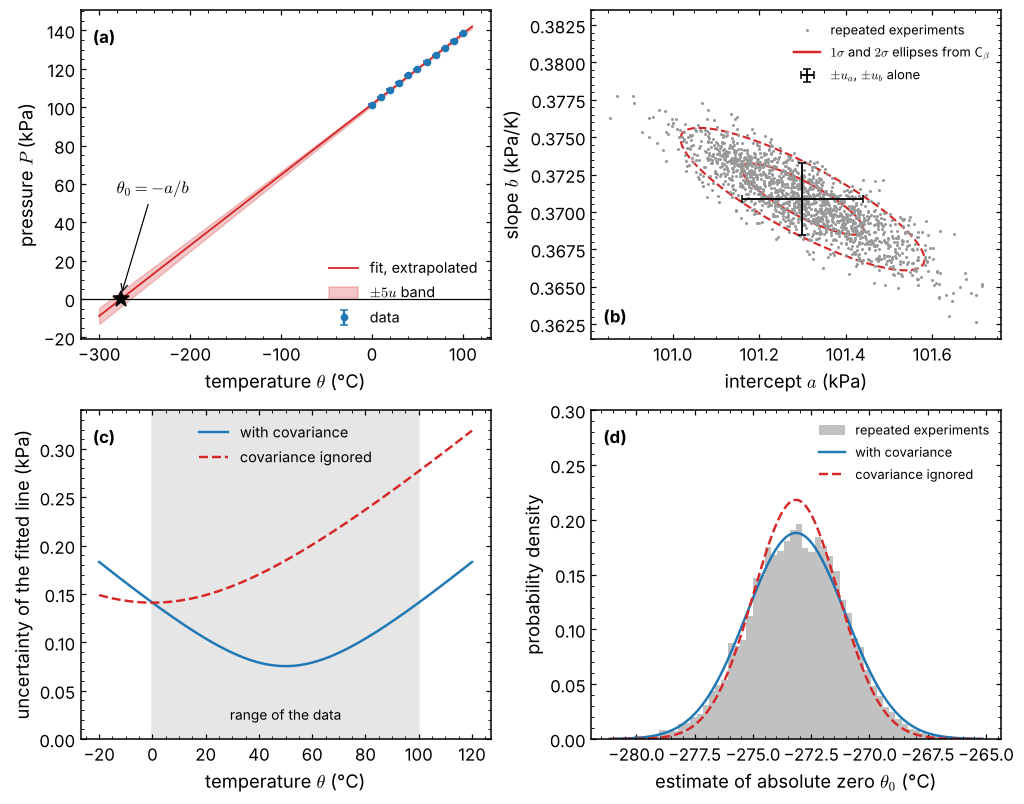

In [5]:
def covariance_ellipse(ax, centre, cov, k, **kw):
    """Ellipse containing the k-sigma contour of a 2-D normal distribution."""
    val, vec = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vec[1, 1], vec[0, 1]))
    ax.add_patch(Ellipse(centre, 2 * k * np.sqrt(val[1]), 2 * k * np.sqrt(val[0]),
                         angle=angle, fill=False, **kw))

fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
tg = np.linspace(-300, 110, 200)
pg, ug = fit.predict(tg)
ax.errorbar(theta, P, yerr=sigma_P, fmt="o", color="C0", ms=4, label="data")
ax.plot(tg, pg, "C3", lw=1.2, label="fit, extrapolated")
ax.fill_between(tg, pg - 5 * ug, pg + 5 * ug, color="C3", alpha=0.25, label=r"$\pm 5u$ band")
ax.axhline(0, color="k", lw=0.8)
ax.plot(th0, 0, "k*", ms=11)
ax.annotate(r"$\theta_0=-a/b$", (th0, 2), (th0 - 5, 55), arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel(r"temperature $\theta$ (°C)"); ax.set_ylabel("pressure $P$ (kPa)")
ax.legend(loc="lower right"); ep.panel_label(ax, "(a)")

ax = axes[0, 1]
ax.plot(ab[:1500, 0], ab[:1500, 1], ".", ms=2, color="0.6", label="repeated experiments")
for k_sig, ls in ((1, "-"), (2, "--")):
    covariance_ellipse(ax, (P0_true, -P0_true / theta0_true), C, k_sig, color="C3", ls=ls, lw=1.4)
ax.plot([], [], "C3-", label=r"$1\sigma$ and $2\sigma$ ellipses from $\mathsf{C}_\beta$")
ax.errorbar(P0_true, -P0_true / theta0_true, xerr=fit.u_intercept, yerr=fit.u_slope,
            fmt="none", color="k", lw=1.2, label=r"$\pm u_a$, $\pm u_b$ alone")
ax.set_xlabel("intercept $a$ (kPa)"); ax.set_ylabel("slope $b$ (kPa/K)")
ax.set_ylim(0.3615, 0.3835)
ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(b)", y=0.10)

ax = axes[1, 0]
tt = np.linspace(-20, 120, 200)
u_with = fit.predict(tt)[1]
u_without = np.sqrt(C[0, 0] + tt**2 * C[1, 1])
ax.plot(tt, u_with, "C0", label="with covariance")
ax.plot(tt, u_without, "C3--", label="covariance ignored")
ax.axvspan(theta.min(), theta.max(), color="0.9", zorder=0)
ax.text(50, 0.02, "range of the data", ha="center", fontsize=9)
ax.set_xlabel(r"temperature $\theta$ (°C)"); ax.set_ylabel("uncertainty of the fitted line (kPa)")
ax.set_ylim(0, 0.34); ax.legend(loc="upper center"); ep.panel_label(ax, "(c)")

ax = axes[1, 1]
bins = np.linspace(theta0_true - 8, theta0_true + 8, 61)
ax.hist(th0_rep, bins=bins, density=True, color="0.6", alpha=0.6, label="repeated experiments")
g = np.linspace(bins[0], bins[-1], 300)
for u_, c, ls, lab in ((u_th0, "C0", "-", "with covariance"), (u_th0_nocov, "C3", "--", "covariance ignored")):
    ax.plot(g, np.exp(-0.5 * ((g - theta0_true) / u_)**2) / (u_ * np.sqrt(2 * np.pi)), c, ls=ls, label=lab)
ax.set_xlabel(r"estimate of absolute zero $\theta_0$ (°C)"); ax.set_ylabel("probability density")
ax.set_ylim(0, 0.30); ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(d)")
plt.show()

**Panel (b)** shows what a covariance matrix means. The fitted pairs
$(a, b)$ from repeated experiments do not fill the rectangle spanned by
$\pm u_a$ and $\pm u_b$ (black cross). They lie along a tilted ellipse: a
fit that returns a high intercept almost always returns a low slope. The
ellipses are drawn from the covariance matrix of the *single* fit above,
and they describe the cloud well.

**Panel (c)**: the uncertainty of the fitted line with and without the
covariance term. With it, the uncertainty has its minimum
$\sigma/\sqrt N$ at the centroid of the data. Without it, the curve has
its minimum at $\theta = 0$ and is more than twice too large in the middle
of the data.

**Panel (d)**: for the absolute zero the error goes the other way. Ignoring
the covariance gives an error bar that is too small, and the histogram of
repeated experiments confirms the value obtained with the covariance.

So the same omission overestimates one derived quantity and
underestimates another. There is no safe direction, and no rule of thumb
replaces the covariance term.

## 13.3 Centring removes the correlation

The correlation between $a$ and $b$ is not a property of the data but of
the way the line was parametrised. Measure $x$ from the centroid instead,

$$ y = a' + b\,(x - \bar x) . $$

Then $a' = \bar y$ is the height of the line at the centroid,
$u_{a'} = \sigma/\sqrt N$, the slope and its uncertainty are unchanged,
and the off-diagonal element of $\mathsf C_\beta$ is proportional to
$\sum(x_i - \bar x) = 0$. The two parameters are uncorrelated and can be
quoted and propagated as independent quantities. (For a weighted fit, use
the weighted mean $\bar x_w$.)

In [6]:
xbar = theta.mean()
fit_c = ep.linear_fit(theta - xbar, P, sigma=sigma_P)
print(fit_c)

# absolute zero from the centred parameters, treated as independent
th0_c, u_th0_c = ep.propagate(lambda ac, b: xbar - ac / b, [fit_c.intercept, fit_c.slope],
                              u=[fit_c.u_intercept, fit_c.u_slope])
print(f"\nabsolute zero from the centred fit, no covariance needed: {th0_c:.2f} +/- {u_th0_c:.2f} C")

intercept = 119.882 +/- 0.075
slope     = 0.367871 +/- 0.0024
correlation(intercept, slope) = +0.000
chi2 / dof = 7.48 / 9 = 0.83

absolute zero from the centred fit, no covariance needed: -275.88 +/- 2.12 C


The result is identical to the one obtained with the full covariance
matrix. Whenever fit parameters are to be published for others to use,
choosing a parametrisation in which they are nearly uncorrelated is a
courtesy to the reader. The Arrhenius example
[Chapter 22](../part5_examples/22_arrhenius_activation_energy.ipynb) shows how much this
matters when $\rho_{ab} = -0.999$.

## 13.4 Transforming the data transforms the weights

Many nonlinear models become straight lines after a transformation: an
exponential decay $y = Ae^{-kt}$ is linear in $\ln y$, a power law in
$\ln y$ against $\ln x$, Michaelis–Menten kinetics in $1/v$ against
$1/[S]$. The transformation also acts on the error bars. By the
one-variable rule of Chapter 3,

$$ u_{\ln y} = \frac{u_y}{y} , \qquad u_{1/y} = \frac{u_y}{y^2} . $$

If the original data have equal absolute uncertainties, the transformed
data do not: for an exponential decay the points in the tail, where $y$
is small, have large uncertainties in $\ln y$ and should count for little.
An unweighted straight-line fit of the transformed data gives every point
the same say, and the noisy tail then dominates the result.

There is a second, subtler effect. The logarithm is curved, so by Section
12.3 symmetric noise in $y$ becomes *biased* noise in $\ln y$:
$\langle\ln y\rangle \approx \ln y_\text{true} - \tfrac12(u_y/y)^2$. In the
tail this pulls the points systematically downwards.

The simulation below generates decay data with constant absolute noise
and estimates $k$ in three ways: (1) unweighted fit of $\ln y$; (2)
weighted fit of $\ln y$ with $\sigma_{\ln y} = \sigma/y$; (3) a nonlinear
least-squares fit of the untransformed data.

In [7]:
A_true, k_true, sigma_y = 1.0, 1.0, 0.02
t = np.linspace(0, 3.0, 16)
decay = lambda t, A, k: A * np.exp(-k * t)

n_rep = 3000
k_est = np.full((n_rep, 3), np.nan)
u_est = np.full((n_rep, 3), np.nan)
n_dropped = 0
for i in range(n_rep):
    y = decay(t, A_true, k_true) + rng.normal(0, sigma_y, t.size)
    ok = y > 0                         # the logarithm cannot take the others
    n_dropped += np.sum(~ok)
    f1 = ep.linear_fit(t[ok], np.log(y[ok]))
    f2 = ep.linear_fit(t[ok], np.log(y[ok]), sigma=sigma_y / y[ok])
    popt, pcov = curve_fit(decay, t, y, p0=[1.0, 1.0], sigma=np.full(t.size, sigma_y),
                           absolute_sigma=True)
    k_est[i] = -f1.slope, -f2.slope, popt[1]
    u_est[i] = f1.u_slope, f2.u_slope, np.sqrt(pcov[1, 1])

print(f"true k = {k_true};  {n_dropped} of {n_rep * t.size} points were non-positive and dropped\n")
print("method                       mean k    bias/k    scatter   typical quoted u")
for j, name in enumerate(("log fit, unweighted", "log fit, weighted", "nonlinear fit")):
    print(f"{name:<26}  {k_est[:, j].mean():.4f}   {k_est[:, j].mean() / k_true - 1:+.2%}    "
          f"{k_est[:, j].std(ddof=1):.4f}     {np.median(u_est[:, j]):.4f}")

true k = 1.0;  26 of 48000 points were non-positive and dropped

method                       mean k    bias/k    scatter   typical quoted u
log fit, unweighted         1.0233   +2.33%    0.0773     0.0432
log fit, weighted           0.9854   -1.46%    0.0238     0.0238
nonlinear fit               0.9992   -0.08%    0.0235     0.0240


The unweighted logarithmic fit is the worst on every count: its scatter is
three times that of the other two, it is biased by about $+2\,\%$, and the
uncertainty it quotes is well below its actual scatter. The weighted
logarithmic fit recovers the precision but keeps a bias of about
$-1.5\,\%$, more than half its standard uncertainty. The reason is that the
weights $\sigma/y$ are computed from the noisy data themselves, so a point
that happened to fluctuate upwards receives a larger weight. The nonlinear
fit of the untransformed data is unbiased to within the noise of the
simulation, and its quoted uncertainty matches its actual scatter.

The general advice follows. Linearising transformations were invented for
graph paper. They remain excellent for *looking* at data, because the eye
judges straightness well. For *estimating* parameters, either fit the
original data with the original model (`scipy.optimize.curve_fit` returns
the covariance matrix in the same form as above), or transform the weights
together with the data.

The exception is data whose noise is proportional to the signal (constant
*relative* uncertainty). Then $u_{\ln y}$ is constant, and the unweighted
fit of $\ln y$ is the correct one. The Arrhenius example (Chapter 22) is of this
kind.

## 13.5 When the error bars are unknown or doubtful

The covariance matrix $(\mathsf A^{\mathsf T}\mathsf W\mathsf A)^{-1}$
scales with the assumed $\sigma_i^2$. It contains no information from the
residuals: double all the error bars and all parameter uncertainties
double, whatever the data do. Two situations must be distinguished.

**The error bars are trusted.** Use them as they are, and use
$\chi^2_\nu$ as a test of the model. In `scipy.optimize.curve_fit` this is
`absolute_sigma=True`; in `ep.linear_fit` it is the default.

**Only the relative weights are known** (or nothing is known and all points
are weighted equally). Then the overall scale is estimated from the
residuals, by multiplying the covariance by $\chi^2_\nu$, which amounts to
assuming that the model is correct. This is `absolute_sigma=False`, the
default of `curve_fit`, and `scale_cov=True` in `ep.linear_fit`. The
goodness-of-fit test is then no longer available, since it has been used
up.

A frequent mistake is to supply carefully estimated error bars and leave
`absolute_sigma` at its default, in which case their absolute size is
silently ignored.

In [8]:
f_abs = ep.linear_fit(theta, P, sigma=2 * sigma_P)                    # error bars doubled, trusted
f_rel = ep.linear_fit(theta, P, sigma=2 * sigma_P, scale_cov=True)    # only relative weights used
print(f"true sigma = {sigma_P} kPa; fit performed with sigma = {2 * sigma_P} kPa")
print(f"  absolute error bars : u_b = {f_abs.u_slope:.5f},  chi2/dof = {f_abs.chi2_red:.2f}  <- suspiciously small")
print(f"  rescaled by chi2/dof: u_b = {f_rel.u_slope:.5f}")
print(f"  fit with the correct sigma: u_b = {fit.u_slope:.5f}")

from scipy.stats import chi2
print(f"\nprobability of a chi-square this small by chance (9 degrees of freedom): {chi2.cdf(f_abs.chi2, f_abs.dof):.3f}")

true sigma = 0.25 kPa; fit performed with sigma = 0.5 kPa
  absolute error bars : u_b = 0.00477,  chi2/dof = 0.21  <- suspiciously small
  rescaled by chi2/dof: u_b = 0.00217
  fit with the correct sigma: u_b = 0.00238

probability of a chi-square this small by chance (9 degrees of freedom): 0.007


With the error bars taken at face value, the slope uncertainty is twice too
large, and the very small $\chi^2_\nu$ is the warning. Rescaling by
$\chi^2_\nu$ brings the uncertainty back to roughly the correct value, at the
price of trusting the model.

## 13.6 Uncertainty in both variables

Ordinary least squares assumes that $x$ is exact. If $x$ is also noisy, two
things happen.

**The error bars are larger than they look.** An error $\delta x$ moves a
point horizontally, which for a line of slope $b$ is equivalent to a
vertical displacement $b\,\delta x$. When the $x$-errors are small compared
with the range of $x$, it is enough to replace each $\sigma_{y,i}^2$ by the
**effective variance**

$$ \sigma_{\text{eff},i}^2 = \sigma_{y,i}^2 + b^2\sigma_{x,i}^2 , $$

using a preliminary estimate of $b$. The pendulum example
[Chapter 20](../part5_examples/20_pendulum_g.ipynb) does this.

**The slope is biased towards zero.** This is less well known and more
dangerous. If the true $x$ values have spread $s_x$ (standard deviation)
and the measurement error of $x$ has standard deviation $\sigma_x$, the
least-squares slope converges not to $b$ but to

$$ b_\text{OLS} \to b\,\frac{s_x^2}{s_x^2 + \sigma_x^2} . $$

The effect is called *attenuation* or *regression dilution*. It does not
shrink with more data, and the quoted $u_b$ gives no hint of it. When the
ratio $\lambda = \sigma_y^2/\sigma_x^2$ of the two error variances is
known, the unbiased alternative is **Deming regression**, which minimises
the weighted perpendicular distances and has the closed form

$$ b = \frac{S_{yy} - \lambda S_{xx} + \sqrt{(S_{yy} - \lambda S_{xx})^2 + 4\lambda S_{xy}^2}}{2S_{xy}} . $$

In [9]:
def deming_slope(x, y, lam):
    Sxx = np.sum((x - x.mean())**2); Syy = np.sum((y - y.mean())**2)
    Sxy = np.sum((x - x.mean()) * (y - y.mean()))
    return (Syy - lam * Sxx + np.sqrt((Syy - lam * Sxx)**2 + 4 * lam * Sxy**2)) / (2 * Sxy)

b_true, sx_err, sy_err = 0.50, 1.0, 0.20
x_true = np.linspace(0, 10, 20)
ols, dem, u_ols = [], [], []
for _ in range(4000):
    xo = x_true + rng.normal(0, sx_err, x_true.size)
    yo = 2.0 + b_true * x_true + rng.normal(0, sy_err, x_true.size)
    f = ep.linear_fit(xo, yo)
    ols.append(f.slope); u_ols.append(f.u_slope)
    dem.append(deming_slope(xo, yo, (sy_err / sx_err)**2))

s2 = x_true.var(ddof=1)
print(f"true slope                         : {b_true}")
print(f"ordinary least squares, mean slope : {np.mean(ols):.4f}   (typical quoted u_b = {np.median(u_ols):.4f})")
print(f"attenuation formula                : {b_true * s2 / (s2 + sx_err**2):.4f}")
print(f"Deming regression, mean slope      : {np.mean(dem):.4f}")

true slope                         : 0.5
ordinary least squares, mean slope : 0.4566   (typical quoted u_b = 0.0357)
attenuation formula                : 0.4533
Deming regression, mean slope      : 0.5021


With an $x$-error of one unit on a range of ten, ordinary least squares
underestimates the slope by 8 to 9 %, close to the prediction of the
attenuation formula (which is exact only for many points), and more than
the quoted $u_b$. Deming regression removes nearly all of the bias. For general problems
with uncertainties in both variables (unequal error bars, nonlinear
models), the keywords are *orthogonal distance regression*, *total least
squares* and, for straight lines with correlated errors, the method of
York.

## Summary

* For linear least squares, $\hat{\boldsymbol\beta}$ is linear in the data
  and $\mathsf C_\beta = (\mathsf A^{\mathsf T}\mathsf W\mathsf A)^{-1}$
  exactly.
* Slope and intercept are correlated, with
  $u_{ab} = -\bar x\sigma^2/S_{xx}$. Derived quantities need the covariance;
  ignoring it can err in either direction.
* Centring the independent variable decorrelates the parameters.
* Transformations change the weights and can introduce bias. Fit the
  original model, or transform the weights too.
* Know whether your error bars are used absolutely or only relatively.
* Errors in $x$ enlarge the effective error bars and bias the slope
  towards zero.

## References

* W. E. Deming, *Statistical Adjustment of Data* (Wiley, 1943).
* D. York, N. M. Evensen, M. López Martínez and J. De Basabe Delgado,
  "Unified equations for the slope, intercept, and standard errors of the
  best straight line", *Am. J. Phys.* **72**, 367 (2004).

## Exercises

1. Derive $u_{P^\ast}$ of Section 13.2 and show that it has its minimum
   $\sigma/\sqrt N$ at $\theta^\ast = \bar\theta$.
2. Repeat the gas-thermometer simulation with data taken only between 0
   and 30 °C (same number of points). How do $\rho_{ab}$ and
   $u_{\theta_0}$ change? Is the distribution of $\theta_0$ still
   symmetric?
3. Fit a parabola to data with `ep.general_linear_fit` and plot the
   $\pm u$ band of the fitted curve, using the full $3\times3$ covariance
   matrix.
4. In Section 13.4, change the noise to be proportional to the signal
   (5 % of $y$). Which of the three methods is now best, and why?
5. For the attenuation example, use the effective-variance weights in an
   ordinary weighted fit. Does this remove the bias? Explain.

---

**Previous:** [12. Covariance and the limits of linearisation](12_covariance_and_limits_of_linearisation.ipynb) &nbsp;·&nbsp; **Next:** [14. Nonlinear least squares](14_nonlinear_least_squares.ipynb)